# Contour / Isarithmic Map

**Family:** Spatial &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Spatial:* Use when precise locations or geographic patterns matter more than anything else.

## Design purpose

Draws lines (isolines) or filled bands joining points of equal value over a continuous surface. The shape of the field (peaks, valleys, gradients) becomes readable, as on topographic and weather maps.

## When to use

- Show a continuous phenomenon that varies smoothly over space (elevation, rainfall, temperature, pollution)
- Show interpolated measurements from sensors or stations
- Show any 2-D function z = f(x, y), including model response surfaces

## Avoid when

- The data is attached to discrete regions (use a choropleth)
- There are too few sample points to justify interpolation

## Alternatives

- Heatmap / raster
- 3-D surface (rarely better)
- Hexbin map

## Design tips

- Use a one-hue sequential scale, light to dark; a rainbow invents boundaries that aren't in the data
- Label a few isolines directly instead of relying only on the color bar
- Mark known reference points (stations, cities) for orientation

## Example

Synthetic annual rainfall (mm) over a 100 × 80 km region with two mountain ranges and five towns.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(4)
x = np.linspace(0, 100, 220); y = np.linspace(0, 80, 180)
X, Y = np.meshgrid(x, y)
def bump(cx, cy, sx, sy, h):
    return h * np.exp(-(((X - cx) / sx) ** 2 + ((Y - cy) / sy) ** 2))
Z = (900 + bump(30, 55, 18, 10, 1600) + bump(75, 25, 12, 16, 1100)
     + bump(55, 70, 25, 8, 500) - 4 * X)
towns = pd.DataFrame({"town": ["Ashford", "Brook", "Calder", "Dunmore", "Elm"],
                      "x": [12, 48, 85, 62, 20], "y": [20, 40, 60, 8, 70]})
towns

,town,x,y
0,Ashford,12,20
1,Brook,48,40
2,Calder,85,60
3,Dunmore,62,8
4,Elm,20,70


### Plot

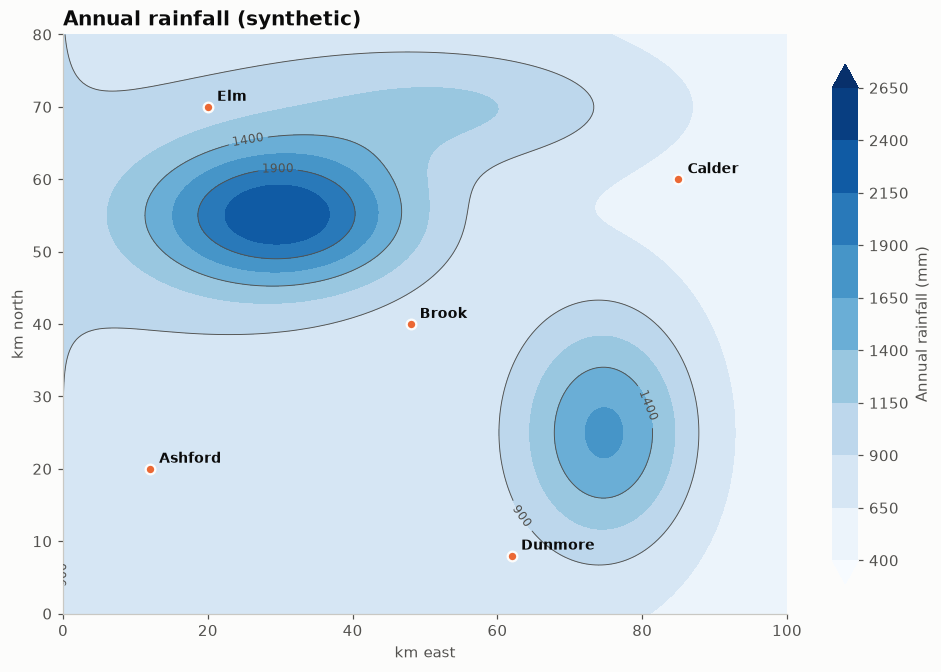

In [3]:
fig, ax = plt.subplots(figsize=(9, 6.2))
levels = np.arange(400, 2700, 250)
cf = ax.contourf(X, Y, Z, levels=levels, cmap=SEQ_CMAP, extend="both")
cs = ax.contour(X, Y, Z, levels=levels[::2], colors="#52514e", linewidths=0.6)
ax.clabel(cs, fmt="%d", fontsize=8)
ax.scatter(towns.x, towns.y, s=40, color=PALETTE[1], edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
for _, t in towns.iterrows():
    ax.annotate(t.town, (t.x, t.y), xytext=(6, 4), textcoords="offset points", fontsize=9,
                fontweight="bold", color="#0b0b0b")
cb = fig.colorbar(cf, ax=ax, shrink=0.85); cb.set_label("Annual rainfall (mm)")
cb.outline.set_visible(False)
ax.set_xlabel("km east"); ax.set_ylabel("km north"); ax.set_aspect("equal")
ax.grid(False)
ax.set_title("Annual rainfall (synthetic)")
fig.tight_layout()
plt.show()

## How to read it

Darker bands get more rain. Closely spaced isolines mark steep gradients, such as the flanks of the north-west range; the far east, away from both ranges, is driest.

---
Standalone script: [`contour_map.py`](contour_map.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)